# 05 Analysis

## Loading libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

os.makedirs("results/figures", exist_ok=True)
AGREE_COL, DISAGREE_COL = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "savefig.dpi": 200})

def add_columns(d):
    d = d.copy()
    d["log_popularity"] = np.log(d["product_n_reviews"])
    d["log_age"] = np.log1p(d["age_days"])
    d["verified"] = d["verified_purchase"].astype(int)
    d["log_length"] = np.log(d["n_words"].clip(lower=1))
    d["log_position"] = np.log1p(d["n_prior"])
    d["repeat"] = d["repeat_reviewer"].astype(int)
    return d

def make_groups(d):
    low = d[(d["rating"] <= 2) & (d["dissent_neg"] | d["agree_neg"])].copy()
    low["disagree"] = low["dissent_neg"].astype(int)
    return {"Low stars (1-2)": low}

df = add_columns(pd.read_parquet("data/processed/features.parquet"))
allrev = pd.read_parquet("data/processed/reviews_clean.parquet")
allrev = add_columns(allrev[allrev["prior_mean"].notna()])

COMP = make_groups(df)
COMP_ALL = make_groups(allrev)
CONTROLS = "C(rating) + log_popularity + log_age + verified"

FEATURES = {"reasons_pct": "Reasons", "mentions_pct": "Mentions of others", "certainty": "Certainty",
            "negation_pct": "Negation", "i_pct": "First-person I",
            "pos_emotion_clean_pct": "Positive emotion", "neg_emotion_clean_pct": "Negative emotion",
            "anger_clean_pct": "Anger", "sadness_clean_pct": "Sadness", "money_clean_pct": "Money"}

def cluster(d):
    return {"groups": pd.factorize(d["parent_asin"])[0]}

print("Reviews with 25+ words:", len(df), "| all reviews with 5+ earlier reviews:", len(allrev))
GROUP_LABELS = {
    "Low stars (1-2)":  {1: "Bad review, good product", 0: "Bad review, bad product"},
}

Reviews with 25+ words: 169384 | all reviews with 5+ earlier reviews: 410866


## Exploratory data analysis

### Class imbalance

     comparison        data  disagree  agree  disagree_share_%  smaller_group  products
Low stars (1-2)   25+ words     16816   2881              85.4           2881      7527
Low stars (1-2) all lengths     36247   7866              82.2           7866     11597


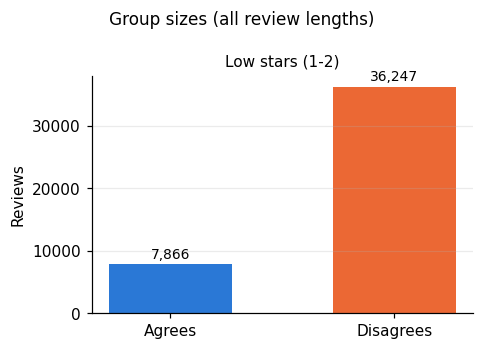

In [2]:
rows = []
for src, comps in [("25+ words", COMP), ("all lengths", COMP_ALL)]:
    for comp, d in comps.items():
        n_dis, n_agr = int(d["disagree"].sum()), int((d["disagree"] == 0).sum())
        rows.append({"comparison": comp, "data": src, "disagree": n_dis, "agree": n_agr,
                     "disagree_share_%": round(n_dis / len(d) * 100, 1),
                     "smaller_group": min(n_dis, n_agr), "products": d["parent_asin"].nunique()})
balance = pd.DataFrame(rows)
balance.to_csv("results/group_sizes.csv", index=False)
print(balance.to_string(index=False))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
for comp, d in COMP_ALL.items():
    counts = [int((d["disagree"] == 0).sum()), int(d["disagree"].sum())]
    bars = ax.bar(["Agrees", "Disagrees"], counts, color=[AGREE_COL, DISAGREE_COL], width=0.55)
    ax.bar_label(bars, labels=[f"{c:,}" for c in counts], padding=2, fontsize=9)
    ax.set_title(comp, fontsize=10)
    ax.set_ylabel("Reviews")
    ax.grid(axis="x", visible=False)
fig.suptitle("Group sizes (all review lengths)", fontsize=11)
fig.tight_layout()
fig.savefig("results/figures/fig_group_sizes.png")
plt.show()

### Feature summary by group

In [3]:
rows = []
for comp, d in COMP.items():
    for col, name in FEATURES.items():
        for g, label in [(0, "agree"), (1, "disagree")]:
            x = d.loc[d["disagree"] == g, col].dropna()
            rows.append({"comparison": comp, "feature": name, "group": label, "n": len(x),
                         "mean": x.mean(), "median": x.median(), "sd": x.std(),
                         "zero_%": (x == 0).mean() * 100})
summary = pd.DataFrame(rows)
summary.to_csv("results/feature_summary_by_group.csv", index=False)
print(summary.round(3).to_string(index=False))

     comparison            feature    group     n  mean  median    sd  zero_%
Low stars (1-2)            Reasons    agree  2881 0.284   0.000 0.809  86.463
Low stars (1-2)            Reasons disagree 16816 0.312   0.000 0.818  83.242
Low stars (1-2) Mentions of others    agree  2881 0.082   0.000 0.445  95.800
Low stars (1-2) Mentions of others disagree 16816 0.079   0.000 0.406  95.272
Low stars (1-2)          Certainty    agree  2501 6.100   6.227 1.010   0.000
Low stars (1-2)          Certainty disagree 14931 6.054   6.175 1.012   0.000
Low stars (1-2)           Negation    agree  2881 3.970   3.509 2.824  13.711
Low stars (1-2)           Negation disagree 16816 3.306   3.030 2.491  16.716
Low stars (1-2)     First-person I    agree  2881 5.245   5.000 3.772  16.418
Low stars (1-2)     First-person I disagree 16816 5.868   5.714 3.760  11.667
Low stars (1-2)   Positive emotion    agree  2881 2.916   2.632 2.703  29.157
Low stars (1-2)   Positive emotion disagree 16816 2.979   2.703 

### Feature distributions

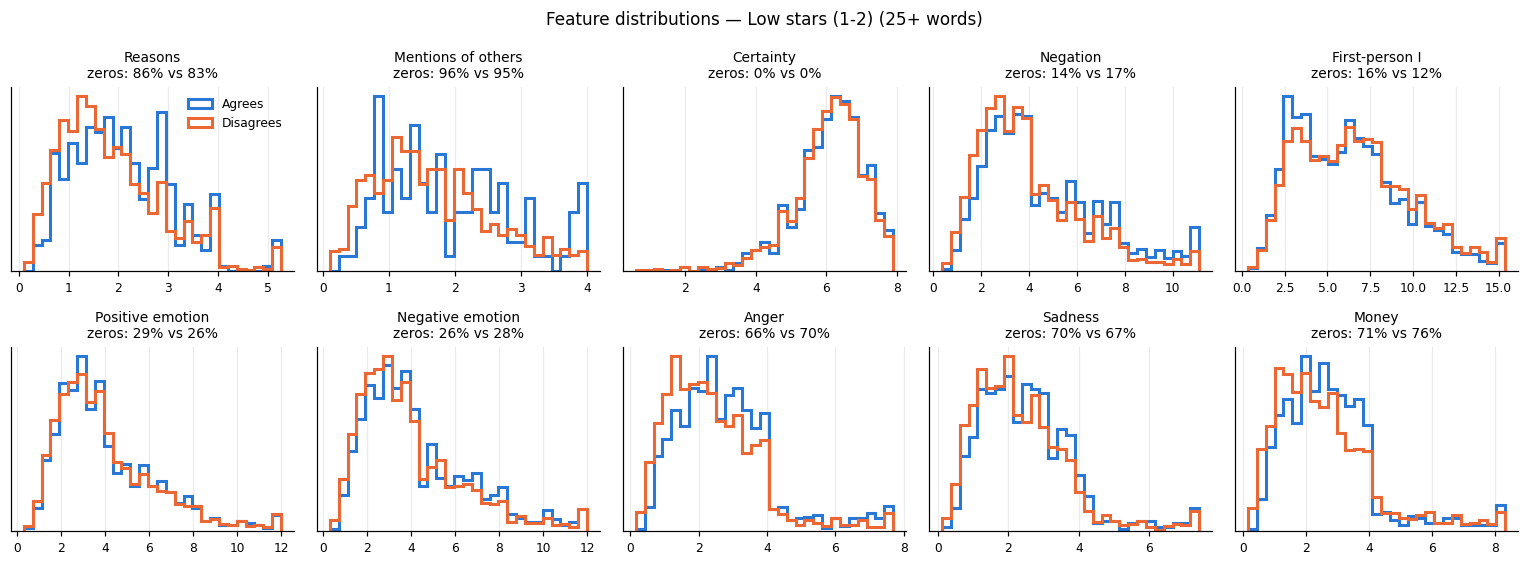

In [4]:
for comp, d in COMP.items():
    fig, axes = plt.subplots(2, 5, figsize=(14, 5.2))
    for ax, (col, name) in zip(axes.ravel(), FEATURES.items()):
        x = d[[col, "disagree"]].dropna()
        z0 = (x.loc[x["disagree"] == 0, col] == 0).mean() * 100
        z1 = (x.loc[x["disagree"] == 1, col] == 0).mean() * 100
        x = x[x[col] > 0]
        top = x[col].quantile(0.99)
        bins = np.linspace(x[col].min(), top, 30)
        for g, colour, label in [(0, AGREE_COL, "Agrees"), (1, DISAGREE_COL, "Disagrees")]:
            ax.hist(x.loc[x["disagree"] == g, col].clip(upper=top), bins=bins, density=True,
                    histtype="step", linewidth=2, color=colour, label=label)
        ax.set_title(f"{name}\nzeros: {z0:.0f}% vs {z1:.0f}%", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_yticks([])
    axes[0, 0].legend(fontsize=8, frameon=False)
    fig.suptitle(f"Feature distributions — {comp} (25+ words)", fontsize=11)
    fig.tight_layout()
    fig.savefig(f"results/figures/fig_distributions_{'low' if comp.startswith('Low') else 'high'}.png")
    plt.show()

### Correlation between features

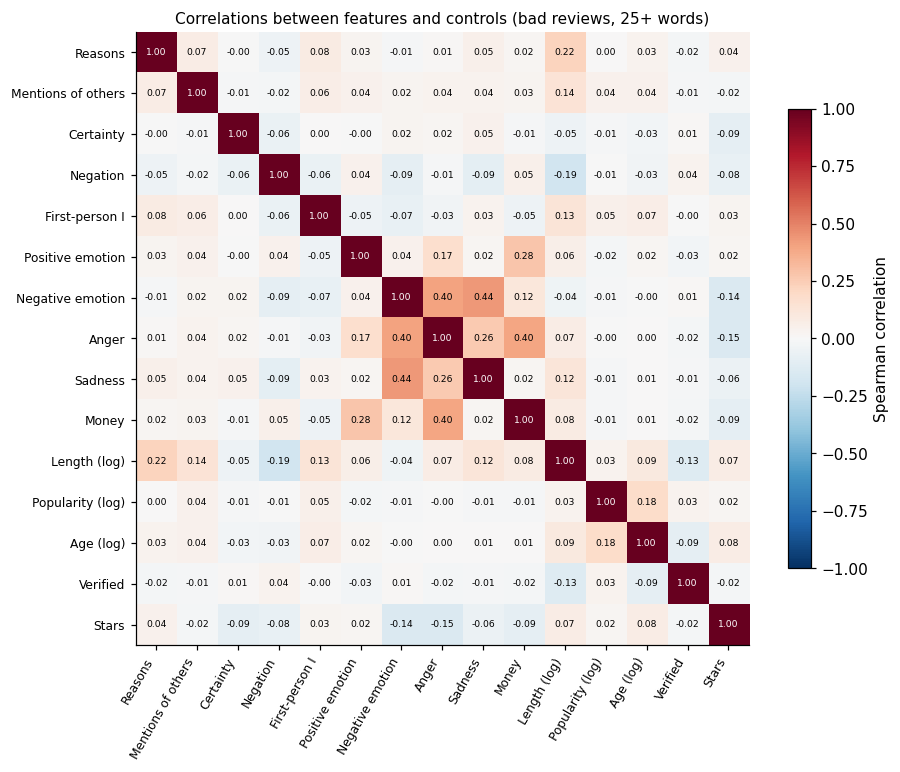

Pairs with |correlation| > 0.7:
none


In [5]:
CORR_COLS = list(FEATURES) + ["log_length", "log_popularity", "log_age", "verified", "rating"]
NAMES = {**FEATURES, "log_length": "Length (log)", "log_popularity": "Popularity (log)",
         "log_age": "Age (log)", "verified": "Verified", "rating": "Stars"}
both = pd.concat(COMP.values())
corr = both[CORR_COLS].corr(method="spearman").rename(index=NAMES, columns=NAMES)
corr.round(3).to_csv("results/correlations_spearman.csv")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman correlation")
ax.set_title("Correlations between features and controls (bad reviews, 25+ words)", fontsize=10)
fig.tight_layout()
fig.savefig("results/figures/fig_correlations.png")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs with |correlation| > 0.7:")
print(pairs[pairs.abs() > 0.7].round(3).to_string() if (pairs.abs() > 0.7).any() else "none")

### Multicollinearity check (VIF)

In [6]:
def vif_table(d, cols, label):
    X = pd.get_dummies(d[cols].dropna(), columns=["rating"], drop_first=True, dtype=float)
    X.insert(0, "const", 1.0)
    return pd.DataFrame([{"model": label, "predictor": c, "VIF": variance_inflation_factor(X.values, i)}
                         for i, c in enumerate(X.columns) if c != "const"])

Q1_COLS = ["disagree", "rating", "log_popularity", "log_age", "verified"]
Q2_WITH = ["log_experience", "repeat", "log_price", "rating", "log_popularity", "log_age", "verified"]
Q2_WITHOUT = [c for c in Q2_WITH if c != "repeat"]

vif = pd.concat([vif_table(d, cols, f"{label} | {comp}")
                 for comp in COMP
                 for d, cols, label in [(COMP[comp], Q1_COLS, "Q1"),
                                        (COMP_ALL[comp], Q2_WITH, "Q2 with repeat"),
                                        (COMP_ALL[comp], Q2_WITHOUT, "Q2 without repeat")]])
vif.to_csv("results/vif.csv", index=False)
print(vif.round(2).to_string(index=False))
print("\nPredictors with VIF above 5:")
print(vif[vif["VIF"] > 5].round(2).to_string(index=False) if (vif["VIF"] > 5).any() else "none")

                              model      predictor  VIF
               Q1 | Low stars (1-2)       disagree 1.06
               Q1 | Low stars (1-2) log_popularity 1.06
               Q1 | Low stars (1-2)        log_age 1.04
               Q1 | Low stars (1-2)       verified 1.01
               Q1 | Low stars (1-2)       rating_2 1.02
   Q2 with repeat | Low stars (1-2) log_experience 6.26
   Q2 with repeat | Low stars (1-2)         repeat 6.21
   Q2 with repeat | Low stars (1-2)      log_price 1.01
   Q2 with repeat | Low stars (1-2) log_popularity 1.03
   Q2 with repeat | Low stars (1-2)        log_age 1.03
   Q2 with repeat | Low stars (1-2)       verified 1.02
   Q2 with repeat | Low stars (1-2)       rating_2 1.01
Q2 without repeat | Low stars (1-2) log_experience 1.01
Q2 without repeat | Low stars (1-2)      log_price 1.01
Q2 without repeat | Low stars (1-2) log_popularity 1.03
Q2 without repeat | Low stars (1-2)        log_age 1.03
Q2 without repeat | Low stars (1-2)       verifi

### Events per predictor

In [7]:
rows = []
checks = [("Q1 any-word (A3)", COMP, None), ("Q2 who disagrees", COMP_ALL, "disagree"),
          ("Q3 any helpful vote", COMP_ALL, "any_helpful")]
for model, comps, outcome in checks:
    for comp, d in comps.items():
        if outcome is None:
            col = min(["anger_clean_pct", "sadness_clean_pct", "money_clean_pct", "mentions_pct"],
                      key=lambda c: (d[c] > 0).sum())
            y = (d[col] > 0).astype(int)
            n_pred = 7
        else:
            s = d.dropna(subset=["log_price"]) if outcome == "disagree" else d
            y = s[outcome].astype(int)
            n_pred = 8 if outcome == "disagree" else 10
        events = int(min(y.sum(), len(y) - y.sum()))
        rows.append({"model": model, "comparison": comp, "n": len(y), "smaller_outcome_group": events,
                     "predictors": n_pred, "cases_per_predictor": round(events / n_pred)})
epv = pd.DataFrame(rows)
epv.to_csv("results/events_per_predictor.csv", index=False)
print(epv.to_string(index=False))

              model      comparison     n  smaller_outcome_group  predictors  cases_per_predictor
   Q1 any-word (A3) Low stars (1-2) 19697                    916           7                  131
   Q2 who disagrees Low stars (1-2) 12803                    765           8                   96
Q3 any helpful vote Low stars (1-2) 44113                  13369          10                 1337


## Writing feature differences (Cohen's d)

In [8]:
def pooled_sd(a, b):
    na, nb = len(a), len(b)
    return np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))

MODELS = {}
rows = []
for comp, d in COMP.items():
    for col, name in FEATURES.items():
        s = d.dropna(subset=[col])
        m = smf.ols(f"{col} ~ disagree + {CONTROLS}", data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
        MODELS[(comp, name)] = m
        sd = pooled_sd(s.loc[s["disagree"] == 1, col], s.loc[s["disagree"] == 0, col])
        lo, hi = m.conf_int().loc["disagree"]
        rows.append({"comparison": comp, "feature": name, "n": len(s),
                     "difference": m.params["disagree"], "ci_low": lo, "ci_high": hi,
                     "d": m.params["disagree"] / sd, "d_low": lo / sd, "d_high": hi / sd,
                     "p": m.pvalues["disagree"]})
q1 = pd.DataFrame(rows)
q1["p_holm"] = q1.groupby("comparison")["p"].transform(lambda p: multipletests(p, method="holm")[1])
q1["significant"] = q1["p_holm"] < 0.05
q1.to_csv("results/q1_word_differences.csv", index=False)
print(q1.drop(columns=["d_low", "d_high"]).round(4).to_string(index=False))

     comparison            feature     n  difference  ci_low  ci_high       d      p  p_holm  significant
Low stars (1-2)            Reasons 19697      0.0245 -0.0074   0.0564  0.0300 0.1318  0.5273        False
Low stars (1-2) Mentions of others 19697     -0.0079 -0.0273   0.0114 -0.0193 0.4197  0.8394        False
Low stars (1-2)          Certainty 17432     -0.0079 -0.0551   0.0392 -0.0078 0.7416  0.8394        False
Low stars (1-2)           Negation 19697     -0.6091 -0.7703  -0.4479 -0.2395 0.0000  0.0000         True
Low stars (1-2)     First-person I 19697      0.4922  0.3109   0.6735  0.1309 0.0000  0.0000         True
Low stars (1-2)   Positive emotion 19697      0.0707 -0.0573   0.1986  0.0263 0.2790  0.8370        False
Low stars (1-2)   Negative emotion 19697     -0.1574 -0.2921  -0.0227 -0.0572 0.0220  0.1319        False
Low stars (1-2)              Anger 19697     -0.1697 -0.2374  -0.1020 -0.1217 0.0000  0.0000         True
Low stars (1-2)            Sadness 19697      

### T-test and Mann-Whitney test

In [9]:
from scipy.stats import ttest_ind, mannwhitneyu

_simple_rows = []
for _comp, _d in COMP.items():
    for _col, _name in FEATURES.items():
        _x = _d[[_col, "disagree"]].dropna()
        _a = _x.loc[_x["disagree"] == 1, _col]
        _b = _x.loc[_x["disagree"] == 0, _col]
        _simple_rows.append({"comparison": _comp, "feature": _name,
                             "mean_disagree": _a.mean(), "mean_agree": _b.mean(),
                             "raw_difference": _a.mean() - _b.mean(),
                             "p_ttest": ttest_ind(_a, _b, equal_var=False).pvalue,
                             "p_mannwhitney": mannwhitneyu(_a, _b, alternative="two-sided").pvalue})
simple_tests = pd.DataFrame(_simple_rows)
simple_tests["p_ttest_holm"] = simple_tests.groupby("comparison")["p_ttest"].transform(lambda p: multipletests(p, method="holm")[1])
simple_tests["p_mw_holm"] = simple_tests.groupby("comparison")["p_mannwhitney"].transform(lambda p: multipletests(p, method="holm")[1])
simple_tests = simple_tests.merge(
    q1[["comparison", "feature", "difference", "p_holm"]].rename(
        columns={"difference": "difference_after_controls", "p_holm": "p_holm_after_controls"}),
    on=["comparison", "feature"], how="left")
print(simple_tests[["comparison", "feature", "raw_difference", "difference_after_controls",
                    "p_ttest_holm", "p_mw_holm", "p_holm_after_controls"]].round(4).to_string(index=False))

     comparison            feature  raw_difference  difference_after_controls  p_ttest_holm  p_mw_holm  p_holm_after_controls
Low stars (1-2)            Reasons          0.0281                     0.0245        0.3424     0.0006                 0.5273
Low stars (1-2) Mentions of others         -0.0030                    -0.0079        1.0000     0.2761                 0.8394
Low stars (1-2)          Certainty         -0.0462                    -0.0079        0.1726     0.0905                 0.8394
Low stars (1-2)           Negation         -0.6647                    -0.6091        0.0000     0.0000                 0.0000
Low stars (1-2)     First-person I          0.6223                     0.4922        0.0000     0.0000                 0.0000
Low stars (1-2)   Positive emotion          0.0627                     0.0707        0.7479     0.2761                 0.8370
Low stars (1-2)   Negative emotion         -0.3168                    -0.1574        0.0000     0.0000                

### Residual check

     comparison            feature  residual_skew  residual_kurtosis    R2
Low stars (1-2)            Reasons          3.103             10.847 0.001
Low stars (1-2) Mentions of others          6.096             42.002 0.002
Low stars (1-2)          Certainty         -1.035              2.467 0.007
Low stars (1-2)           Negation          0.844              1.121 0.015
Low stars (1-2)     First-person I          0.396             -0.112 0.007
Low stars (1-2)   Positive emotion          1.046              1.477 0.001
Low stars (1-2)   Negative emotion          1.137              1.867 0.022
Low stars (1-2)              Anger          2.296              8.009 0.025
Low stars (1-2)            Sadness          2.327              9.390 0.006
Low stars (1-2)              Money          2.823             10.548 0.009


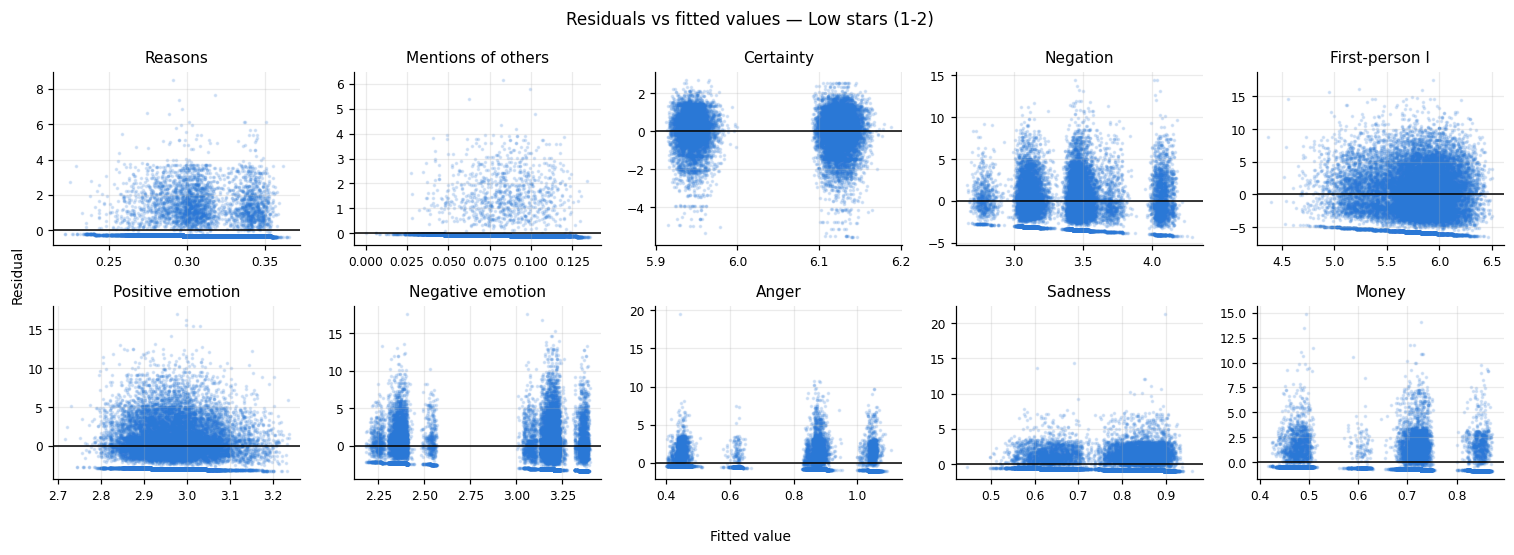

In [10]:
rows = []
for (comp, name), m in MODELS.items():
    r = m.resid
    rows.append({"comparison": comp, "feature": name, "residual_skew": r.skew(),
                 "residual_kurtosis": r.kurt(), "R2": m.rsquared})
resid = pd.DataFrame(rows)
resid.to_csv("results/q1_residual_checks.csv", index=False)
print(resid.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for ax, name in zip(axes.ravel(), FEATURES.values()):
    m = MODELS[("Low stars (1-2)", name)]
    ax.scatter(m.fittedvalues, m.resid, s=2, alpha=0.15, color=AGREE_COL)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(name, fontsize=10)
    ax.tick_params(labelsize=8)
fig.supxlabel("Fitted value", fontsize=9)
fig.supylabel("Residual", fontsize=9)
fig.suptitle("Residuals vs fitted values — Low stars (1-2)", fontsize=11)
fig.tight_layout()
fig.savefig("results/figures/fig_residuals_low.png")
plt.show()

### At least one word (logistic regression)

In [11]:
rows = []
for comp, d in COMP.items():
    for col in ["anger_clean_pct", "sadness_clean_pct", "money_clean_pct", "mentions_pct"]:
        s = d.dropna(subset=[col]).copy()
        s["has_word"] = (s[col] > 0).astype(int)
        m = smf.logit(f"has_word ~ disagree + {CONTROLS}", data=s).fit(disp=0, cov_type="cluster", cov_kwds=cluster(s))
        lo, hi = np.exp(m.conf_int().loc["disagree"])
        rows.append({"comparison": comp, "feature": FEATURES[col],
                     "share_agree": s.loc[s["disagree"] == 0, "has_word"].mean(),
                     "share_disagree": s.loc[s["disagree"] == 1, "has_word"].mean(),
                     "odds_ratio": np.exp(m.params["disagree"]), "ci_low": lo, "ci_high": hi,
                     "p": m.pvalues["disagree"]})
q1z = pd.DataFrame(rows)
q1z["p_holm"] = q1z.groupby("comparison")["p"].transform(lambda p: multipletests(p, method="holm")[1])
q1z.to_csv("results/q1_any_word.csv", index=False)
print(q1z.round(4).to_string(index=False))

     comparison            feature  share_agree  share_disagree  odds_ratio  ci_low  ci_high      p  p_holm
Low stars (1-2)              Anger       0.3429          0.2953      0.8711  0.7941   0.9555 0.0034  0.0069
Low stars (1-2)            Sadness       0.2957          0.3276      1.2142  1.0931   1.3487 0.0003  0.0012
Low stars (1-2)              Money       0.2857          0.2410      0.8389  0.7535   0.9338 0.0013  0.0040
Low stars (1-2) Mentions of others       0.0420          0.0473      1.0161  0.8103   1.2741 0.8899  0.8899


### Review length

In [12]:
rows = []
for comp, d in COMP_ALL.items():
    m = smf.ols(f"log_length ~ disagree + {CONTROLS}", data=d).fit(cov_type="cluster", cov_kwds=cluster(d))
    lo, hi = m.conf_int().loc["disagree"]
    rows.append({"comparison": comp, "n": len(d),
                 "median_words_agree": d.loc[d["disagree"] == 0, "n_words"].median(),
                 "median_words_disagree": d.loc[d["disagree"] == 1, "n_words"].median(),
                 "percent_longer": (np.exp(m.params["disagree"]) - 1) * 100,
                 "ci_low_%": (np.exp(lo) - 1) * 100, "ci_high_%": (np.exp(hi) - 1) * 100,
                 "p": m.pvalues["disagree"]})
q1len = pd.DataFrame(rows)
q1len.to_csv("results/q1_length.csv", index=False)
print(q1len.round(4).to_string(index=False))

     comparison     n  median_words_agree  median_words_disagree  percent_longer  ci_low_%  ci_high_%   p
Low stars (1-2) 44113                17.0                   22.0         18.4841   13.7964     23.365 0.0


## Reviewer experience and price

In [13]:
rows = []
for comp, d in COMP_ALL.items():
    s = d.dropna(subset=["log_price"])
    m = smf.logit(f"disagree ~ log_experience + log_price + {CONTROLS}",
                  data=s).fit(disp=0, cov_type="cluster", cov_kwds=cluster(s))
    ci = np.exp(m.conf_int())
    for var, name in [("log_experience", "Experience (log)"), ("log_price", "Price (log)")]:
        rows.append({"comparison": comp, "n": len(s), "n_no_price_dropped": len(d) - len(s),
                     "price_coverage_%": round(len(s) / len(d) * 100, 1),
                     "variable": name, "odds_ratio": np.exp(m.params[var]),
                     "ci_low": ci.loc[var, 0], "ci_high": ci.loc[var, 1], "p": m.pvalues[var]})
q2 = pd.DataFrame(rows)
q2.to_csv("results/q2_who_disagrees.csv", index=False)
print(q2.round(4).to_string(index=False))

     comparison     n  n_no_price_dropped  price_coverage_%         variable  odds_ratio  ci_low  ci_high      p
Low stars (1-2) 12803               31310              29.0 Experience (log)      1.5566  1.0480   2.3119 0.0284
Low stars (1-2) 12803               31310              29.0      Price (log)      1.4702  1.0135   2.1328 0.0423


## Helpful votes

In [14]:
Q3_CONTROLS = CONTROLS + " + log_position + log_length"
rows = []
for comp, d in COMP_ALL.items():
    d = d.assign(any_vote=d["any_helpful"].astype(int))
    m1 = smf.logit(f"any_vote ~ disagree + {Q3_CONTROLS}", data=d).fit(disp=0, cov_type="cluster", cov_kwds=cluster(d))
    lo1, hi1 = np.exp(m1.conf_int().loc["disagree"])
    voted = d[d["helpful_vote"] > 0]
    m2 = smf.negativebinomial(f"helpful_vote ~ disagree + {Q3_CONTROLS}",
                              data=voted).fit(disp=0, maxiter=200, cov_type="cluster", cov_kwds=cluster(voted))
    lo2, hi2 = np.exp(m2.conf_int().loc["disagree"])
    rows.append({"comparison": comp, "n": len(d), "share_any_vote_agree": d.loc[d["disagree"] == 0, "any_vote"].mean(),
                 "share_any_vote_disagree": d.loc[d["disagree"] == 1, "any_vote"].mean(),
                 "odds_ratio_any_vote": np.exp(m1.params["disagree"]), "or_ci_low": lo1, "or_ci_high": hi1,
                 "p_any_vote": m1.pvalues["disagree"],
                 "n_with_votes": len(voted), "rate_ratio_votes": np.exp(m2.params["disagree"]),
                 "rr_ci_low": lo2, "rr_ci_high": hi2, "p_votes": m2.pvalues["disagree"],
                 "nb_converged": m2.mle_retvals.get("converged", None)})
q3 = pd.DataFrame(rows)
q3.to_csv("results/q3_helpfulness.csv", index=False)
print(q3.round(4).T.to_string())

                                       0
comparison               Low stars (1-2)
n                                  44113
share_any_vote_agree              0.1866
share_any_vote_disagree           0.3283
odds_ratio_any_vote               1.9477
or_ci_low                         1.6436
or_ci_high                        2.3081
p_any_vote                           0.0
n_with_votes                       13369
rate_ratio_votes                   1.069
rr_ci_low                         0.9069
rr_ci_high                        1.2601
p_votes                           0.4267
nb_converged                        True


## Price check

In [15]:
rows = []
for comp, d in COMP.items():
    for col, name in FEATURES.items():
        s = d.dropna(subset=[col, "log_price"])
        a = smf.ols(f"{col} ~ disagree + {CONTROLS}", data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
        b = smf.ols(f"{col} ~ disagree + log_price + {CONTROLS}", data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
        main = q1[(q1["comparison"] == comp) & (q1["feature"] == name)].iloc[0]
        rows.append({"comparison": comp, "result": f"Q1 {name}", "n_priced": len(s),
                     "main_all_data": main["difference"], "main_significant": main["significant"],
                     "priced_no_price": a.params["disagree"], "priced_with_price": b.params["disagree"],
                     "p_with_price": b.pvalues["disagree"]})
for comp, d in COMP_ALL.items():
    s = d.dropna(subset=["log_price"]).assign(any_vote=lambda x: x["any_helpful"].astype(int))
    a = smf.logit(f"any_vote ~ disagree + {Q3_CONTROLS}", data=s).fit(disp=0, cov_type="cluster", cov_kwds=cluster(s))
    b = smf.logit(f"any_vote ~ disagree + log_price + {Q3_CONTROLS}", data=s).fit(disp=0, cov_type="cluster", cov_kwds=cluster(s))
    main = q3[q3["comparison"] == comp].iloc[0]
    rows.append({"comparison": comp, "result": "Q3 any helpful vote (odds ratio)", "n_priced": len(s),
                 "main_all_data": main["odds_ratio_any_vote"], "main_significant": main["p_any_vote"] < 0.05,
                 "priced_no_price": np.exp(a.params["disagree"]), "priced_with_price": np.exp(b.params["disagree"]),
                 "p_with_price": b.pvalues["disagree"]})
rob = pd.DataFrame(rows)
rob["no_effect_value"] = np.where(rob["result"].str.startswith("Q3"), 1, 0)
rob["same_direction"] = (np.sign(rob["priced_no_price"] - rob["no_effect_value"]) ==
                         np.sign(rob["priced_with_price"] - rob["no_effect_value"]))
rob.to_csv("results/robustness_price.csv", index=False)
print(rob.round(4).to_string(index=False))

     comparison                           result  n_priced  main_all_data  main_significant  priced_no_price  priced_with_price  p_with_price  no_effect_value  same_direction
Low stars (1-2)                       Q1 Reasons      5871         0.0245             False           0.0353             0.0335        0.4584                0            True
Low stars (1-2)            Q1 Mentions of others      5871        -0.0079             False          -0.0379            -0.0389        0.1408                0            True
Low stars (1-2)                     Q1 Certainty      5200        -0.0079             False           0.1199             0.1087        0.1085                0            True
Low stars (1-2)                      Q1 Negation      5871        -0.6091              True          -0.6370            -0.6275        0.0026                0            True
Low stars (1-2)                Q1 First-person I      5871         0.4922              True           0.4648             0.45

## Effect size plot

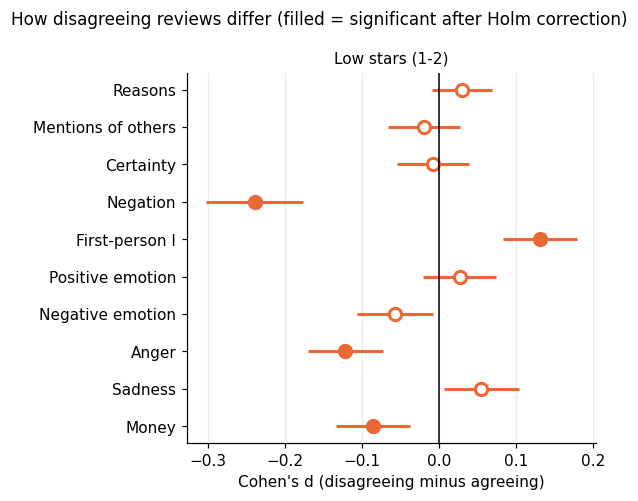

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 4.6))
names = list(FEATURES.values())[::-1]
for comp in COMP:
    t = q1[q1["comparison"] == comp].set_index("feature").loc[names]
    y = np.arange(len(t))
    ax.hlines(y, t["d_low"], t["d_high"], color=DISAGREE_COL, linewidth=2)
    for yi, (_, r) in zip(y, t.iterrows()):
        ax.plot(r["d"], yi, "o", markersize=8, color=DISAGREE_COL,
                markerfacecolor=DISAGREE_COL if r["significant"] else "white", markeredgewidth=2)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y, names)
    ax.set_title(comp, fontsize=10)
    ax.set_xlabel("Cohen's d (disagreeing minus agreeing)")
    ax.grid(axis="y", visible=False)
fig.suptitle("How disagreeing reviews differ (filled = significant after Holm correction)", fontsize=11)
fig.tight_layout()
fig.savefig("results/figures/fig_q1_effect_sizes.png")
plt.show()

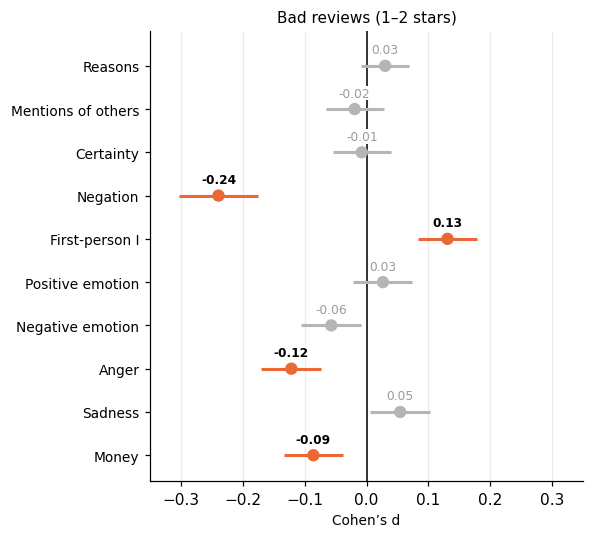

In [17]:
TITLES = {"Low stars (1-2)": "Bad reviews (1–2 stars)"}
names = list(FEATURES.values())[::-1]
fig, ax = plt.subplots(figsize=(5.5, 5))
for comp in COMP:
    t = q1[q1["comparison"] == comp].set_index("feature").loc[names]
    y = np.arange(len(t))
    colours = np.where(t["significant"], "#eb6834", "#b5b5b5")
    ax.axvline(0, color="black", linewidth=1)
    ax.hlines(y, t["d_low"], t["d_high"], color=colours, linewidth=2)
    ax.scatter(t["d"], y, s=50, color=colours, zorder=3)
    for yi, d, s in zip(y, t["d"], t["significant"]):
        label = f"{d:.2f}".replace("-0.00", "0.00")
        ax.text(d, yi + 0.22, label, ha="center", va="bottom", fontsize=8, zorder=4,
                color="black" if s else "#9a9a9a", fontweight="bold" if s else "normal",
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    ax.set_xlim(-0.35, 0.35)
    ax.set_ylim(-0.6, len(t) - 0.2)
    ax.set_yticks(y, names, fontsize=9)
    ax.set_title(TITLES[comp], fontsize=10)
    ax.set_xlabel("Cohen’s d", fontsize=9)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("results/figures/fig_q1_effect_sizes_labelled.png", bbox_inches="tight")
plt.show()